# 02 – Velocity: mô phỏng dữ liệu đổ về liên tục

**Velocity** (tốc độ) là chữ V nói về việc dữ liệu **đến nhanh và liên tục**, và hệ thống phải xử lý kịp. Dataset FIFA là dữ liệu tĩnh, nên notebook này **mô phỏng** dữ liệu đến theo thời gian thực:

- **Bên gửi (producer):** cứ vài giây lại "thả" dữ liệu của **một phiên bản FIFA** (15 → 23, mỗi phiên bản khoảng 1 triệu bản ghi) vào thư mục `/fifa/stream/landing` trên HDFS. Đây giống như một đợt dữ liệu mới vừa được hệ thống nguồn gửi về.
- **Bên xử lý:** dùng **Spark Structured Streaming**, cứ 2 giây kiểm tra thư mục một lần. Thấy file mới thì xử lý ngay theo từng **lô nhỏ (micro-batch)** và cập nhật bảng thống kê trực tiếp.

Ta đo 3 con số cho mỗi đợt:
1. **Tốc độ nạp vào HDFS** (MB/s): thời gian chép đợt dữ liệu lên HDFS.
2. **Tốc độ xử lý** (bản ghi/giây): lấy từ báo cáo tiến độ của Spark.
3. **Độ trễ đầu-cuối** (giây): từ lúc dữ liệu chạm HDFS đến lúc kết quả xuất hiện trong bảng.

> **Cần chạy `01_variety_parquet.ipynb` trước**, vì notebook này lấy dữ liệu từ `/fifa/curated/players_parquet`.
> Ngoài đời thật, bên gửi thường là **Kafka** hoặc **Flume**. Ở đây ta dùng thư mục HDFS cho gọn, nhưng cơ chế xử lý của Spark thì giống hệt.

Cả notebook mất khoảng **3–6 phút**.

In [1]:
import os, time, json
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

BASE    = os.environ.get("FIFA_BASE", "hdfs://namenode:8020")
SOURCE  = f"{BASE}/fifa/curated/players_parquet/gender=male"   # tao boi notebook 01
STREAM  = f"{BASE}/fifa/stream"
LANDING = f"{STREAM}/landing"        # thu muc Spark theo doi
STAGING = f"{STREAM}/_staging"       # cho tam truoc khi "tha" vao landing
CKPT    = f"{STREAM}/_checkpoint"    # Spark ghi lai tien do de chiu loi
RESULTS = os.environ.get("FIFA_RESULTS", "/home/jovyan/work/results")
INTERVAL_S = 8                       # khoang nghi giua 2 dot du lieu
os.makedirs(RESULTS, exist_ok=True)

builder = (SparkSession.builder.appName("02-velocity-streaming")
           .config("spark.driver.memory", "3g")
           .config("spark.sql.shuffle.partitions", "8")
           .config("spark.sql.streaming.numRecentProgressUpdates", "500"))
if BASE.startswith("hdfs://"):
    builder = builder.config("spark.hadoop.fs.defaultFS", BASE)
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")

jvm, hconf = spark._jvm, spark._jsc.hadoopConfiguration()
Path = jvm.org.apache.hadoop.fs.Path
fs = Path(BASE + "/").getFileSystem(hconf)
MB = 1024 * 1024

if not fs.exists(Path(SOURCE)):
    raise RuntimeError("Chua co /fifa/curated/players_parquet. Hay chay notebook 01_variety_parquet truoc.")

# Moi lan chay lai thi xoa sach du lieu stream cu
fs.delete(Path(STREAM), True)
fs.mkdirs(Path(LANDING)); fs.mkdirs(Path(STAGING))

versions = sorted(int(st.getPath().getName().split("=")[1])
                  for st in fs.listStatus(Path(SOURCE)) if st.getPath().getName().startswith("fifa_version="))
print("Se gui lan luot cac phien ban:", versions)

Se gui lan luot cac phien ban: [15, 16, 17, 18, 19, 20, 21, 22, 23]


## Bên gửi: thả một đợt dữ liệu vào HDFS

Mỗi đợt được chép vào `_staging` trước, rồi **đổi tên (rename) một phát** sang `landing`. Rename trên HDFS là thao tác **nguyên tử** (chỉ sửa metadata ở NameNode), nên Spark không bao giờ đọc phải một file đang chép dở. Đây là cách làm chuẩn khi nạp file cho Spark Streaming.

In [2]:
def deliver(v):
    src = Path(f"{SOURCE}/fifa_version={v}")
    tmp = Path(f"{STAGING}/fifa_version={v}")
    dst = Path(f"{LANDING}/fifa_version={v}")
    nbytes = fs.getContentSummary(src).getLength()
    t0 = time.perf_counter()
    jvm.org.apache.hadoop.fs.FileUtil.copy(fs, src, fs, tmp, False, hconf)
    t_copy = time.perf_counter() - t0
    fs.rename(tmp, dst)
    return {"fifa_version": v, "MB": round(nbytes / MB, 1), "giay_nap": round(t_copy, 2),
            "MB_per_s_nap": round(nbytes / MB / t_copy, 1), "_landed_at": time.perf_counter()}

# Dot dau tien phai co san truoc khi bat stream (de Spark nhan ra cot phan vung fifa_version)
deliveries = [deliver(versions[0])]
print(deliveries[0])

{'fifa_version': 15, 'MB': 108.3, 'giay_nap': 1.27, 'MB_per_s_nap': 85.0, '_landed_at': 6311.72188064}


## Bên xử lý: Spark Structured Streaming

Truy vấn dưới đây chạy **liên tục ở chế độ nền**. Mỗi khi có lô mới, nó cập nhật bảng `live_stats`: số bản ghi, overall trung bình và giá trị cầu thủ cao nhất của từng phiên bản. Mở http://localhost:4040 → tab **Structured Streaming** để xem biểu đồ tốc độ trực tiếp của Spark.

In [3]:
schema = spark.read.parquet(SOURCE).schema
stream_df = spark.readStream.schema(schema).parquet(LANDING)

live = (stream_df.groupBy("fifa_version")
        .agg(F.count("*").alias("so_ban_ghi"),
             F.round(F.avg("overall"), 2).alias("overall_tb"),
             F.max("value_eur").alias("gia_tri_max_eur")))

query = (live.writeStream.outputMode("complete").format("memory").queryName("live_stats")
         .option("checkpointLocation", CKPT)
         .trigger(processingTime="2 seconds").start())
print("Stream dang chay, id =", query.id)

Stream dang chay, id = 66bf8fab-5e05-406e-8ca0-0360e9077819


In [4]:
def wait_for(v, landed_at, timeout=300):
    # Cho den khi phien ban v xuat hien trong bang ket qua -> do do tre dau-cuoi
    while time.perf_counter() - landed_at < timeout:
        if spark.sql(f"SELECT 1 FROM live_stats WHERE fifa_version = {v}").count() > 0:
            return round(time.perf_counter() - landed_at, 2)
        time.sleep(0.3)
    raise TimeoutError(f"FIFA {v} chua duoc xu ly sau {timeout}s - xem loi trong query.exception()")

def report(d):
    print(f"FIFA {d['fifa_version']}: {d['MB']:7.1f} MB | nap {d['giay_nap']:5.2f}s ({d['MB_per_s_nap']:6.1f} MB/s)"
          f" | co ket qua sau {d['do_tre_giay']:5.2f}s")

deliveries[0]["do_tre_giay"] = wait_for(versions[0], deliveries[0]["_landed_at"]); report(deliveries[0])
for v in versions[1:]:
    time.sleep(INTERVAL_S)
    d = deliver(v)
    d["do_tre_giay"] = wait_for(v, d["_landed_at"]); report(d)
    deliveries.append(d)

print("\nBang thong ke truc tiep sau dot cuoi:")
spark.sql("SELECT * FROM live_stats ORDER BY fifa_version").show()

FIFA 15:   108.3 MB | nap  1.27s (  85.0 MB/s) | co ket qua sau  8.76s
FIFA 16:   113.5 MB | nap  1.37s (  83.1 MB/s) | co ket qua sau  2.42s
FIFA 17:   186.0 MB | nap  2.34s (  79.6 MB/s) | co ket qua sau  3.10s
FIFA 18:   175.2 MB | nap  1.94s (  90.3 MB/s) | co ket qua sau  1.49s
FIFA 19:   144.3 MB | nap  1.61s (  89.5 MB/s) | co ket qua sau  2.45s
FIFA 20:   132.4 MB | nap  1.31s ( 101.2 MB/s) | co ket qua sau  2.67s
FIFA 21:   159.0 MB | nap  1.72s (  92.6 MB/s) | co ket qua sau  2.28s
FIFA 22:   162.4 MB | nap  1.73s (  93.7 MB/s) | co ket qua sau  2.34s
FIFA 23:    21.5 MB | nap  0.25s (  86.9 MB/s) | co ket qua sau  1.58s

Bang thong ke truc tiep sau dot cuoi:
+------------+----------+----------+---------------+
|fifa_version|so_ban_ghi|overall_tb|gia_tri_max_eur|
+------------+----------+----------+---------------+
|          15|    962549|     63.83|      100500000|
|          16|    986175|     65.23|      111000000|
|          17|   1601431|     66.17|      109000000|
|   

## Kết quả: tốc độ từng lô

Lô đầu tiên thường có độ trễ cao hơn, vì Spark còn phải khởi động truy vấn và đọc schema. Các lô sau mới phản ánh tốc độ thật của hệ thống.

In [5]:
prog = [p for p in query.recentProgress if p["numInputRows"] > 0]
batches = pd.DataFrame([{
    "batch_id": p["batchId"],
    "so_ban_ghi": p["numInputRows"],
    "ban_ghi_per_s_xu_ly": round(p.get("processedRowsPerSecond") or 0),
    "giay_xu_ly": round(p["durationMs"].get("triggerExecution", 0) / 1000, 2),
} for p in prog])

dl = pd.DataFrame(deliveries).drop(columns="_landed_at")
# Moi dot du lieu = mot lo co du lieu (dot sau chi gui khi dot truoc da xu ly xong)
velocity = pd.concat([dl.reset_index(drop=True), batches.reset_index(drop=True)], axis=1)
velocity.to_csv(f"{RESULTS}/velocity_streaming.csv", index=False)

tong = velocity.so_ban_ghi.sum()
print(f"Tong: {tong:,} ban ghi trong {len(velocity)} lo | "
      f"xu ly TB {velocity.ban_ghi_per_s_xu_ly.mean():,.0f} ban ghi/s | "
      f"nap TB {velocity.MB_per_s_nap.mean():.1f} MB/s | do tre TB {velocity.do_tre_giay.mean():.1f}s")
velocity

Tong: 10,003,590 ban ghi trong 9 lo | xu ly TB 1,054,239 ban ghi/s | nap TB 89.1 MB/s | do tre TB 3.0s


,fifa_version,MB,giay_nap,MB_per_s_nap,do_tre_giay,batch_id,so_ban_ghi,ban_ghi_per_s_xu_ly,giay_xu_ly
0,15,108.3,1.27,85.0,8.76,0,962549,322462,2.98
1,16,113.5,1.37,83.1,2.42,1,986175,531631,1.85
2,17,186.0,2.34,79.6,3.10,2,1601431,1333415,1.20
3,18,175.2,1.94,90.3,1.49,3,1512360,1585283,0.95
4,19,144.3,1.61,89.5,2.45,4,1229986,1498156,0.82
5,20,132.4,1.31,101.2,2.67,5,1128336,1352921,0.83
6,21,159.0,1.72,92.6,2.28,6,1197628,1330698,0.90
7,22,162.4,1.73,93.7,2.34,7,1218451,1321530,0.92
8,23,21.5,0.25,86.9,1.58,8,166674,212053,0.79


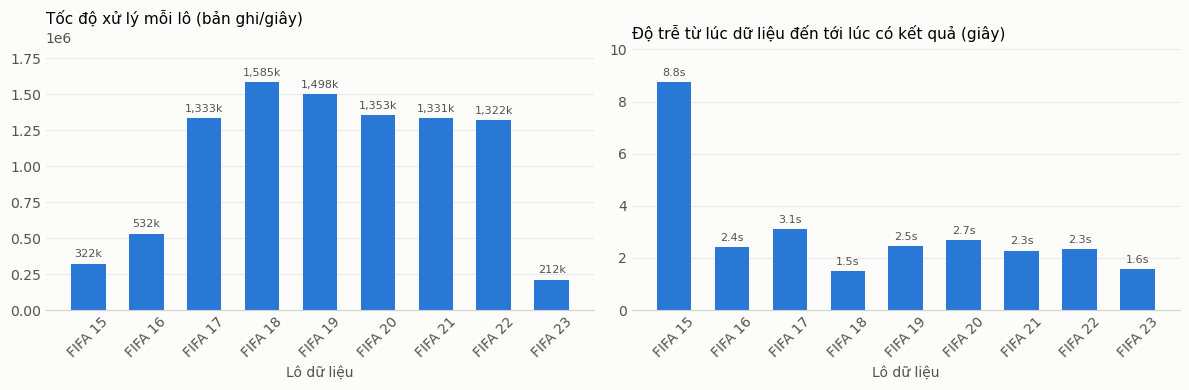

In [6]:
def style(ax, title, xlabel):
    ax.set_facecolor("#fcfcfb")
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel, color="#52514e")
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color("#d4d3cd"); ax.tick_params(colors="#52514e", length=0)
    ax.grid(axis="y", color="#ebeae5", linewidth=0.8); ax.set_axisbelow(True)

labels = [f"FIFA {v}" for v in velocity.fifa_version]
fig, axes = plt.subplots(1, 2, figsize=(12, 4), facecolor="#fcfcfb")
b = axes[0].bar(labels, velocity.ban_ghi_per_s_xu_ly, color="#2a78d6", width=0.6)
axes[0].bar_label(b, labels=[f"{v/1000:,.0f}k" for v in velocity.ban_ghi_per_s_xu_ly], padding=3, fontsize=8, color="#52514e")
style(axes[0], "Tốc độ xử lý mỗi lô (bản ghi/giây)", "Lô dữ liệu")
b = axes[1].bar(labels, velocity.do_tre_giay, color="#2a78d6", width=0.6)
axes[1].bar_label(b, labels=[f"{v:.1f}s" for v in velocity.do_tre_giay], padding=3, fontsize=8, color="#52514e")
style(axes[1], "Độ trễ từ lúc dữ liệu đến tới lúc có kết quả (giây)", "Lô dữ liệu")
for ax in axes: ax.tick_params(axis="x", rotation=45); ax.margins(y=0.15)
plt.tight_layout(); plt.savefig(f"{RESULTS}/velocity_streaming.png", dpi=150); plt.show()

In [7]:
# Dung stream khi da xong (chay o nay truoc khi tat may / chay lai notebook)
query.stop()
print("Da dung stream.")
# Muon xoa du lieu stream de tiet kiem dung luong HDFS thi bo dau # o dong duoi:
# fs.delete(Path(STREAM), True)

Da dung stream.


## Tổng kết cho báo cáo

File `notebooks/results/velocity_streaming.csv` và `velocity_streaming.png`, cùng với `reports/velocity/io_benchmark.csv` (từ `scripts/demo-velocity.bat`), là 2 phần số liệu cho Velocity.

Câu chốt gợi ý (điền số từ kết quả của bạn):
> *Mô phỏng 9 đợt dữ liệu (FIFA 15 → 23, tổng ___ triệu bản ghi) đổ về HDFS liên tục. Spark Structured Streaming xử lý trung bình ___ bản ghi/giây mỗi lô, và kết quả sẵn sàng sau trung bình ___ giây kể từ khi dữ liệu đến. Tốc độ ghi HDFS đo được ___ MB/s (replication 3), tốc độ đọc ___ MB/s; khi mất 1 DataNode thì tốc độ đọc còn ___ MB/s nhưng dữ liệu vẫn đầy đủ.*